In [40]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from keras import layers
from keras.models import Sequential

# Dataset Creation
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [41]:
# Dataset
X, y = make_moons(
    n_samples=1000,
    noise=0.25,
    random_state=42
    )

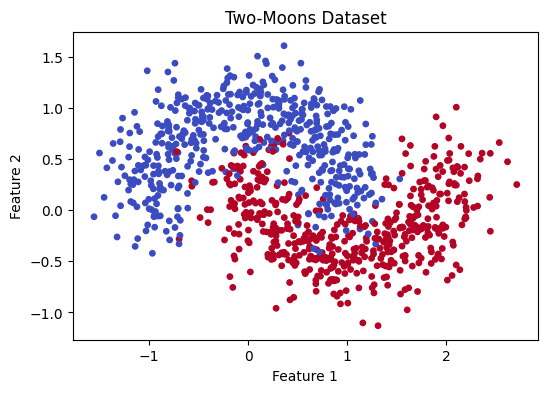

In [42]:
# Visualize dataset
plt.figure(figsize=(6, 4))
plt.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm", s=15)
plt.title("Two-Moons Dataset")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

In [43]:
# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
    )

In [44]:
# Standardize
scalar = StandardScaler()

# X_train = scalar.fit(X_train)
# X_train = scalar.transform(X_train)
X_train = scalar.fit_transform(X_train)
X_test = scalar.transform(X_test)

In [45]:
X_train.shape[1], X_train

(2,
 array([[-0.34189481, -0.83663912],
        [-0.05144356,  0.84282426],
        [ 1.92210135,  0.08214942],
        ...,
        [ 0.87355794, -0.36459264],
        [ 0.64424835,  0.55581131],
        [ 0.21182197, -1.9011506 ]]))

In [46]:
# Configuration
ACTIVATION = "relu" #"elu"
INITIALIZER = "he_normal"

tf.keras.utils.set_random_seed(42)

In [47]:
# Build model
model = Sequential()
model.add(layers.Dense(16, activation=ACTIVATION, kernel_initializer=INITIALIZER, input_shape=[2]))
model.add(layers.Dense(16, activation=ACTIVATION, kernel_initializer=INITIALIZER))
model.add(layers.Dense(1, activation="sigmoid"))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [48]:
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_6 (Dense)                 │ (None, 16)             │            48 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 16)             │           272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 337 (1.32 KB)

 Trainable params: 337 (1.32 KB)

 Non-trainable params: 0 (0.00 B)

In [49]:
# Compile
model.compile(
    loss="binary_crossentropy",
    optimizer="adam",
    metrics=["accuracy"]
    )

In [50]:
# Training
history = model.fit(
    X_train,
    y_train,
    epochs=30,
    validation_split=0.2,
    verbose=True
    )

Epoch 1/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 3s 15ms/step - accuracy: 0.6094 - loss: 0.5824 - val_accuracy: 0.7625 - val_loss: 0.4729
Epoch 2/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7437 - loss: 0.4763 - val_accuracy: 0.8875 - val_loss: 0.3841
Epoch 3/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8203 - loss: 0.4195 - val_accuracy: 0.8875 - val_loss: 0.3324
Epoch 4/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8188 - loss: 0.3870 - val_accuracy: 0.8875 - val_loss: 0.3002
Epoch 5/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8172 - loss: 0.3675 - val_accuracy: 0.9000 - val_loss: 0.2791
Epoch 6/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8172 - loss: 0.3556 - val_accuracy: 0.9000 - val_loss: 0.2653
Epoch 7/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8172 - loss: 0.3480 - val_accuracy: 0.9000 - val_loss: 0.2563
Epoch 8/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8188 - loss: 0.3427 - val_accuracy: 0.9000 - val_loss

In [51]:
# Evaluate
test_loss, test_accuracy = model.evaluate(
    X_test, y_test, verbose=0
)

print(f"\nActivation: {ACTIVATION}")
print(f"Initializer: {INITIALIZER}")
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")


Activation: relu
Initializer: he_normal
Test Loss: 0.1893
Test Accuracy: 0.9250


In [52]:
# Visualize

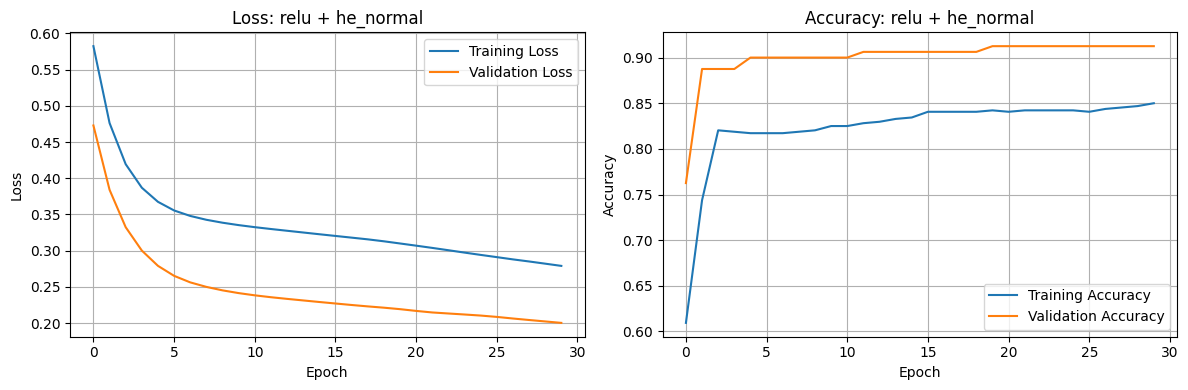

In [53]:
plt.figure(figsize=(12, 4))

# Loss
plt.subplot(1, 2, 1)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title(f"Loss: {ACTIVATION} + {INITIALIZER}")
plt.legend()
plt.grid(True)

# Accuracy
plt.subplot(1, 2, 2)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title(f"Accuracy: {ACTIVATION} + {INITIALIZER}")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()